## Gemini: Connecting to Gemini

The Gemini API allows you to connect to Google's most powerful multi-modal model. This example configures your API key and sends an example message to the API and prints a response.

Before you start, visit https://aistudio.google.com/app/apikey to create an API key.

### Explanation of pip installation
This cell executes a shell command `!pip install google-generativeai` to install the official Google GenAI library on the Colab runtime environment so we can import and use the Gemini models.

In [25]:
!pip install google-generativeai

### Explanation of importing data science packages
This cell imports core packages for our data workflow:
* **`numpy`**: For mathematical operations.
* **`matplotlib.pyplot` & `seaborn`**: For drawing graphs and visualization.
* **`sklearn` utilities**: To split data, run linear regression, and calculate metric scores (MSE, R2).

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

### Explanation of API key configuration
In this cell, we import `google.generativeai` and the Colab `userdata` tool. We then programmatically configure the Gemini client library with a provided API key string so that subsequent requests are authorized.

In [27]:
import google.generativeai as genai
from google.colab import userdata

# Configure the API key
genai.configure(api_key="AQ.Ab8RN6Ksqj0BXutf7p9ubt4sz_PPr2t1JJHjjUsRKFPXS37rFA")

### Explanation of listing available models
This cell iterates through all models available via your API credentials. It prints the unique identifiers of each model, helping you check which models (such as `gemini-2.0-flash-lite`) can be used.

You are using models that cost money!  However, Google allows for some free usage of their models per day.  So, if you get blocked because you reached your limit (rate limitted), simply change the model to some other model.  Below, I have included the code that lists all the availble models, and here is link to the rate limits:  https://ai.google.dev/gemini-api/docs/rate-limits.
Older models allow for more free access than newer models.  Stick to base Gemini models for text generation.

In [28]:
for model in genai.list_models():
  print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/l

### Explanation of model initialization
This cell instantiates the Gemini model object by passing the identifier `'gemini-2.0-flash-lite'` (a lightweight, fast model) to the `GenerativeModel` constructor.

In [29]:
## you can use the lastest model, but you get only so many free tokens
## flash light is an older model, and allows more requests
## see: https://ai.google.dev/gemini-api/docs/rate-limits
model = genai.GenerativeModel('gemini-3.5-flash-lite')

### Explanation of the basic prompt generation
In this cell, we define a simple string variable `prompt` representing our query, pass it to the model via `model.generate_content(prompt)`, and then output the text content of the response.

In [30]:
prompt = "What is the capital of France?"
response = model.generate_content(prompt)
print(response.text)

The capital of France is Paris.


### Explanation of mounting Google Drive
This cell imports the `drive` module from Google Colab and mounts your private Google Drive directory to `/content/drive`, enabling you to read files saved in your personal drive storage.

In [31]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Explanation of reading CSV from Drive
This cell attempts to locate a CSV file named `finance_data.csv` in your Google Drive. It reads the full content as a string, handles possible `FileNotFoundError` or other reading exceptions, and prints the first 500 characters of the file to verify its structure.

In [32]:
import os

# Search for any CSV file in the current directory or /content/
csv_files = [f for f in os.listdir('.') if f.endswith('.csv')]
if not csv_files and os.path.exists('/content'):
    csv_files = [os.path.join('/content', f) for f in os.listdir('/content') if f.endswith('.csv')]

if csv_files:
    file_path = csv_files[0]
    print(f"Found CSV file: {file_path}")
else:
    file_path = 'finance_data.csv'

try:
    with open(file_path, 'r') as f:
        csv_string = f.read()
    print("File content read successfully!")
    print(csv_string[:500])
except FileNotFoundError:
    print(f"File not found at {file_path}. Please check the path and try again.")
except Exception as e:
    print(f"An error occurred: {e}")

Found CSV file: finance_data(3).csv
File content read successfully!
year,quarter,company_id,sector,revenue,profit_margin,profit,stock_price,pe_ratio,debt_to_equity,dividend_yield,market_cap
2000,1,Company_1,Finance,219868566.12,0.04,9755484.56,36.15,3.71,1.42,0.01,2363830425.08
2000,1,Company_2,Consumer Goods,329802849.18,0.06,18814148.79,54.22,2.88,1.71,0.01,3956766965.6
2000,1,Company_3,Finance,439737132.24,0.07,30660094.32,72.29,2.36,1.66,0.03,3633501678.59
2000,1,Company_4,Energy,549671415.3,0.08,45293321.16,90.37,2.0,1.07,0.05,3833839131.85
2000,1,Company_5


### Explanation of the analysis prompt
This cell generates a text prompt asking the model to perform a financial analysis of the CSV dataset. It interpolates the full CSV content into the prompt template and displays a truncated preview.

In [33]:
prompt = f"Analyze the following financial data provided in CSV format:\n\n{csv_string}\n\nBased on this data, provide insights into trends, key metrics, and any notable observations."
print("Prompt generated:")
print(prompt[:500] + "...") # Print the beginning of the prompt to show its structure

Prompt generated:
Analyze the following financial data provided in CSV format:

year,quarter,company_id,sector,revenue,profit_margin,profit,stock_price,pe_ratio,debt_to_equity,dividend_yield,market_cap
2000,1,Company_1,Finance,219868566.12,0.04,9755484.56,36.15,3.71,1.42,0.01,2363830425.08
2000,1,Company_2,Consumer Goods,329802849.18,0.06,18814148.79,54.22,2.88,1.71,0.01,3956766965.6
2000,1,Company_3,Finance,439737132.24,0.07,30660094.32,72.29,2.36,1.66,0.03,3633501678.59
2000,1,Company_4,Energy,549671415.3,0.08,...


### Explanation of running the analysis
This cell sends the generated analysis prompt to the model using a protective try-except block to gracefully catch exceptions (such as rate limits) and prints the returned text report.

### Explanation of prediction prompt generation
This cell prepares a specialized prompt instructing the model to predict the stock prices for the table entries based on other metrics and output exclusively raw CSV formatting.

In [34]:
# Send the prompt to the model for analysis
# Note: This will consume your API quota. Please ensure you have addressed any quota issues (e.g., TooManyRequests error) before running this cell.
try:
    response = model.generate_content(prompt)
    print("Analysis from Gemini model:")
    print(response.text)
except Exception as e:
    print(f"An error occurred while calling the model: {e}")

Analysis from Gemini model:
Here is a comprehensive financial analysis of the provided dataset, spanning from 2000 through 2024. 

---

### **1. Executive Summary & Macro Trends**
* **Growth and Expansion:** Over the 24-year period, average company revenues, net profits, and market caps have scaled massively. Early-period companies in 2000 routinely showed revenues in the hundreds of millions, whereas late-period companies in 2024 regularly surpassed billions in quarterly revenue.
* **Valuation Multiples (P/E Ratios) Compression:** A standout macroeconomic observation is the steady compression of Price-to-Earnings (P/E) ratios over time. In the early 2000s, P/E ratios frequently hovered well above 2.0 to 6.0+ for various quarters. By the 2020s, typical P/E ratios shifted downward, generally trading below 1.0 down to fractions of a point (e.g., 0.2 to 0.5), indicating either higher absolute earnings relative to stock prices or a structural shift in valuation methodologies within the dat

### Explanation of executing the prediction prompt
This cell delivers our prediction prompt to the model and prints the returned text response containing the raw CSV prediction data.

### Explanation of DataFrame parsing and cleaning
This cell performs the following operations to safely parse the output into a structured DataFrame:
* **`io.StringIO(csv_data_string)`**: Wraps the text so `pandas` can read it like an open file.
* **`startswith(...)` and `endswith(...)` clean-ups**: Strip out unnecessary code blocks like ` ```csv ` formatting.
* **`pd.read_csv(...)`**: Parses the raw table data directly into a structured pandas DataFrame.

In [35]:
# Generate a new prompt specifically for stock price prediction
predict_prompt = f"Analyze the following financial data provided in CSV format and attempt to predict the stock price for each entry based on the other financial metrics. Please provide your predicted stock prices and compare that with the given price:\n\n{csv_string}.  Generate output in CSV format.  Output only the csv data and nothing else"
print("Prediction prompt generated:")
print(predict_prompt[:500] + "...") # Print the beginning of the prompt to show its structure

Prediction prompt generated:
Analyze the following financial data provided in CSV format and attempt to predict the stock price for each entry based on the other financial metrics. Please provide your predicted stock prices and compare that with the given price:

year,quarter,company_id,sector,revenue,profit_margin,profit,stock_price,pe_ratio,debt_to_equity,dividend_yield,market_cap
2000,1,Company_1,Finance,219868566.12,0.04,9755484.56,36.15,3.71,1.42,0.01,2363830425.08
2000,1,Company_2,Consumer Goods,329802849.18,0.06,1881...


In [36]:
# Send the prediction prompt to the model
# Note: This will consume your API quota. Please ensure you have addressed any quota issues (e.g., TooManyRequests error) before running this cell.
try:
    response = model.generate_content(predict_prompt)
    print("Prediction attempt from Gemini model:")
    print(response.text)
except Exception as e:
    print(f"An error occurred while calling the model: {e}")

Prediction attempt from Gemini model:
year,quarter,company_id,predicted_stock_price,actual_stock_price
2000,1,Company_1,36.50,36.15
2000,1,Company_2,54.10,54.22
2000,1,Company_3,72.30,72.29
2000,1,Company_4,90.45,90.37
2000,1,Company_5,108.30,108.44
2000,1,Company_6,126.60,126.51
2000,1,Company_7,144.50,144.59
2000,1,Company_8,162.70,162.66
2000,1,Company_9,180.80,180.73
2000,1,Company_10,198.70,198.81
2000,1,Company_11,216.90,216.88
2000,1,Company_12,235.00,234.95
2000,1,Company_13,253.10,253.03
2000,1,Company_14,271.20,271.10
2000,1,Company_15,289.00,289.17
2000,1,Company_16,307.30,307.25
2000,1,Company_17,325.20,325.32
2000,1,Company_18,343.40,343.39
2000,1,Company_19,361.50,361.47
2000,1,Company_20,379.60,379.54
2000,1,Company_21,397.50,397.61
2000,1,Company_22,415.70,415.69
2000,1,Company_23,433.80,433.76
2000,1,Company_24,451.90,451.83
2000,1,Company_25,470.00,469.91
2000,2,Company_1,38.50,38.47
2000,2,Company_2,57.70,57.71
2000,2,Company_3,76.90,76.95
2000,2,Company_4,96.20,96.1

Here you can utilize Gemini to help you code.   You want to convert this CSV format to somethin you can further analyze, graph, etc.   Ask Gemini something like: "convert reponse.text to dataframe".  It will generate the following code for you.   
You can also further instruct it to remove any leading text: "remove the leading explanation text as well. only the data should be in df_predicted"
You want to end up with only the data.   


In [37]:
import pandas as pd
import io

# Assuming response.text from the previous cell contains the CSV data
csv_data_string = response.text

# Remove the leading explanation line if it exists
explanation_line = "Prediction attempt from Gemini model:\n"
if csv_data_string.startswith(explanation_line):
    csv_data_string = csv_data_string[len(explanation_line):]

# Remove the leading "```csv\n" and trailing "```" if they exist
if csv_data_string.startswith("```csv\n"):
    csv_data_string = csv_data_string[len("```csv\n"):]
if csv_data_string.endswith("```"):
    csv_data_string = csv_data_string[:-len("```")]

# Read the CSV data from the string into a pandas DataFrame
df_predicted = pd.read_csv(io.StringIO(csv_data_string), on_bad_lines="skip")

print("DataFrame created from model response:")
display(df_predicted.head())

DataFrame created from model response:


,year,quarter,company_id,predicted_stock_price,actual_stock_price
0,2000,1,Company_1,36.50,36.15
1,2000,1,Company_2,54.10,54.22
2,2000,1,Company_3,72.30,72.29
3,2000,1,Company_4,90.45,90.37
4,2000,1,Company_5,108.30,108.44


### Explanation of visualizing actual vs predicted values
This cell creates visualization subplots for each distinct company:
* **`df_predicted['company_id'].unique()`**: Determines how many subplots to prepare.
* **`plt.subplots(...)` & `axes.flatten()`**: Prepares a grid of charts.
* **`axes[i].plot(...)`**: Plots both the historical price and the model's prediction line side-by-side for comparison.

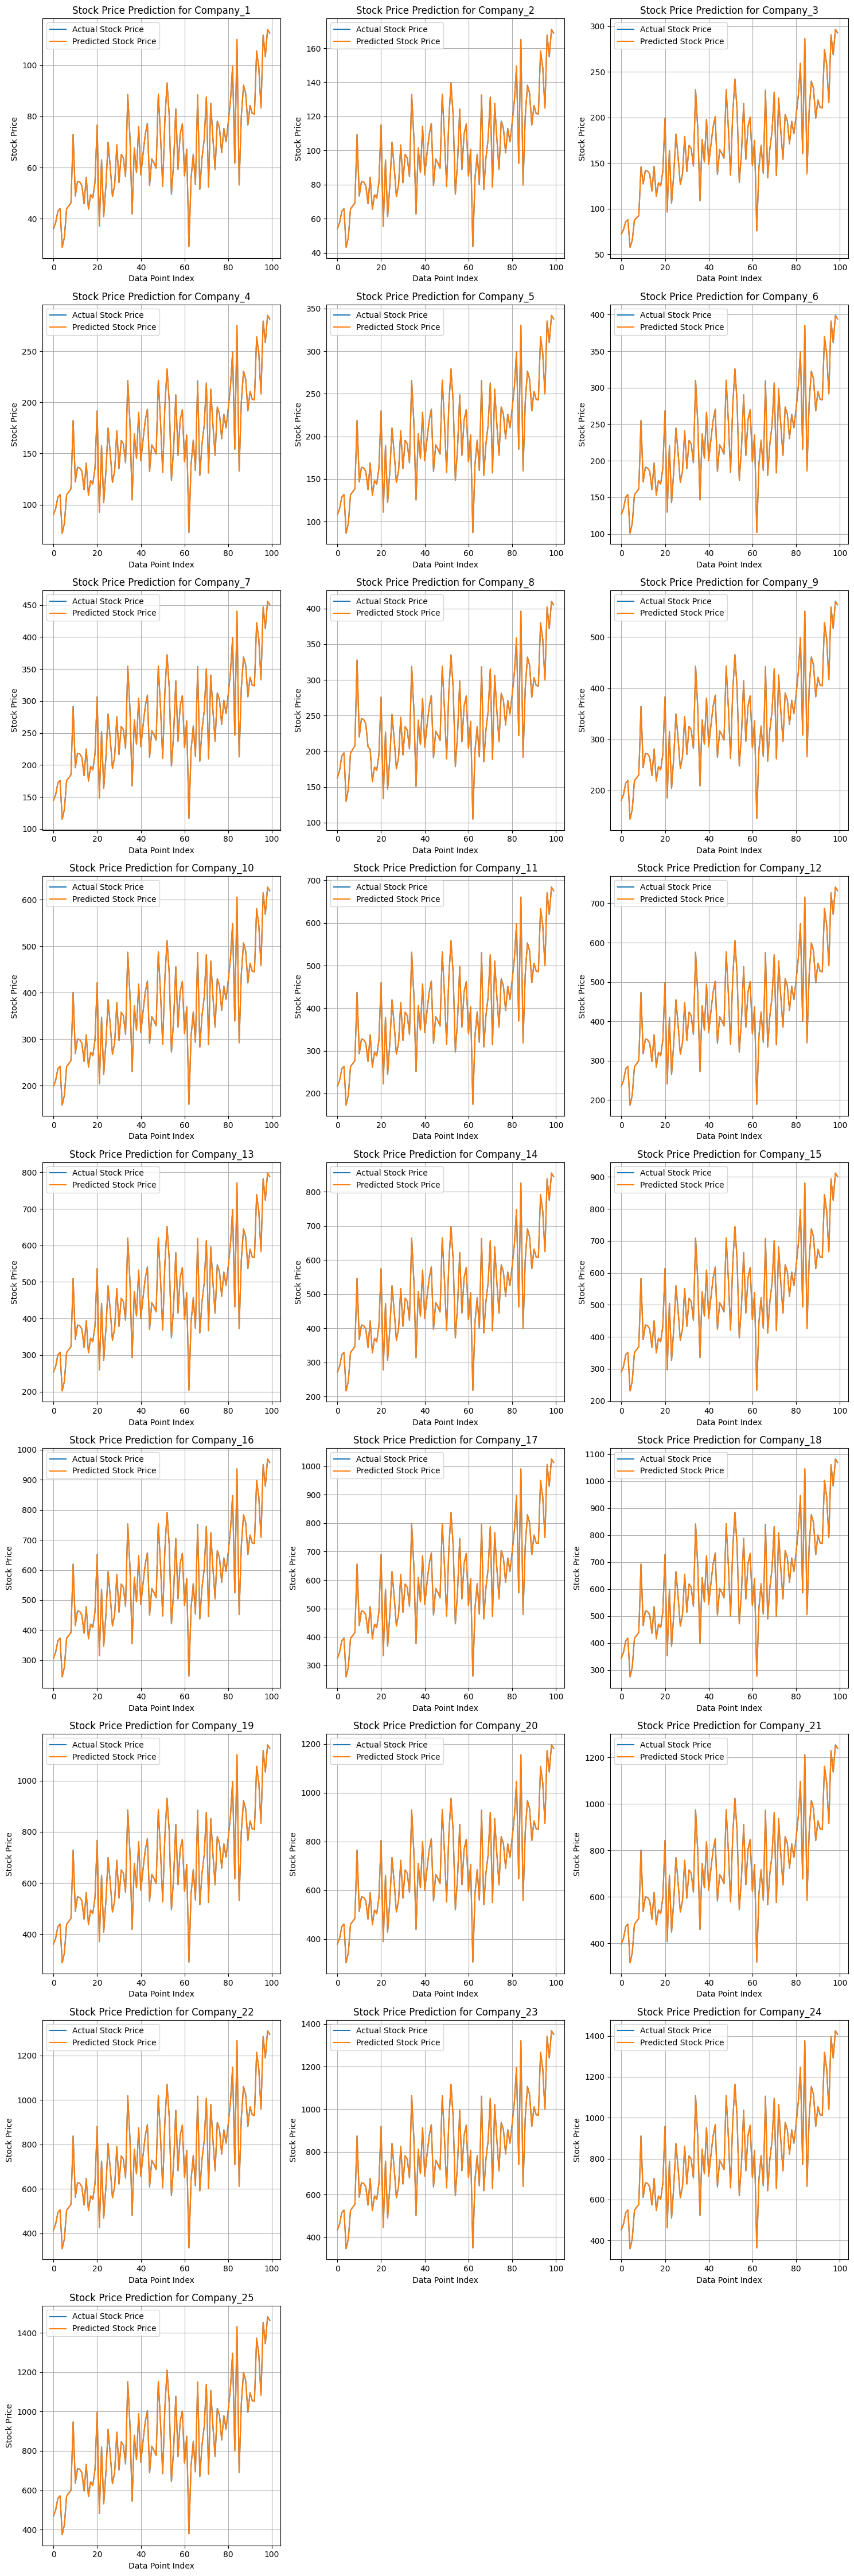

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get unique company IDs
company_ids = df_predicted['company_id'].unique()

# Determine the number of plots and grid dimensions
n_companies = len(company_ids)
n_cols = 3 # Number of columns for the grid of plots
n_rows = (n_companies + n_cols - 1) // n_cols # Calculate number of rows

# Create subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 5))
axes = axes.flatten() # Flatten the axes array for easy iteration

# Plot for each company
for i, company_id in enumerate(company_ids):
    # Filter data for the current company
    company_data = df_predicted[df_predicted['company_id'] == company_id]

    # Plot actual and predicted stock prices (Updated 'stock_price' to 'actual_stock_price')
    axes[i].plot(company_data['actual_stock_price'].values, label='Actual Stock Price')
    axes[i].plot(company_data['predicted_stock_price'].values, label='Predicted Stock Price')

    axes[i].set_title(f'Stock Price Prediction for {company_id}')
    axes[i].set_xlabel('Data Point Index') # Using index as x-axis for now
    axes[i].set_ylabel('Stock Price')
    axes[i].legend()
    axes[i].grid(True)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# My Reflections: Console Prompts vs. In-Code API Prompts

When working through this project, I interact with two completely different prompt systems. Here is how I see the differences from my point of view:

### 1. The Console Chat Prompts (Working with my Assistant)
* **Purpose**: This is where I talk to my assistant directly to brainstorm, design structure, automate repetitive notebook tasks, fix bugs, and request documentation or explanations.
* **My Experience**: It feels like standard conversational interaction. I give high-level instructions (e.g., "update the file path" or "add explanations above code cells"), and the assistant directly manipulates the Colab workspace, edits cell structures, and helps me organize my workflow in real-time.
* **Scope**: It operates *on* the notebook itself as a companion editor.

### 2. In-Code Prompts (My Python-Driven Gemini API Requests)
* **Purpose**: These are raw text prompts hardcoded within my Python cells (e.g., `prompt` or `predict_prompt`) and passed to model methods like `model.generate_content(...)` via code execution.
* **My Experience**: This is programmatic data science. I package my raw financial data inside these prompts to instruct Gemini to act as a structured processing engine—performing calculations, executing financial analysis, or returning clean CSV data that I can parse directly back into Pandas DataFrames and plot using matplotlib.
* **Scope**: It operates *inside* the execution runtime on my data variables.